# Coefficients after variable selection

When a model chooses its own predictors, the coefficients it reports are not
ordinary estimates. A term is retained because it looked large in this sample,
so its reported magnitude reflects both any underlying effect and the selection
that picked it out.

This study measures that distortion in a setting where the true answer is
known, and then compares bootstrap coefficient intervals, stability selection and conformal
prediction, which address different sources of uncertainty.

A selected coefficient needs a different interpretation from a prespecified one. The first fit establishes the problem; the resampling and conformal
sections are extensions that measure selection stability and predictive coverage.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | what a coefficient means once the model chose the term itself |
| **Observed response** | a simulated continuous outcome |
| **Estimand** | the coefficient of a selected term — and the selected coefficient is not an unbiased estimate of the underlying effect |
| **Units** | simulated, arbitrary scale; the true coefficients are set in the notebook |
| **Sampling unit** | one simulated observation |
| **Dependence** | independent by construction |
| **Split / resampling unit** | the observation; stability selection resamples rows |
| **Tuning** | `mstop` fixed so the selection effect is visible rather than tuned away |
| **Uncertainty** | stability selection frequencies and a conformal interval |
| **Claim type** | methodological. It is a statement about the estimator, demonstrated on data whose truth is known |
:::


## The data

The data are simulated with every true coefficient set to zero. In that setting
any selected predictor is a false positive. Repeating the simulation therefore
measures how often a procedure selects noise.

The generator produces 100 observations and 40 predictors, all independent
standard normal, with a response drawn independently of all of them. Each fit runs 200 boosting steps (`mstop`, the number of steps) with step length 0.1 (`nu`, the fraction of each selected term's fit added per step).


In [1]:
import numpy as np
import polars as pl
# Fix the random draw so the resampling result is reproducible.
import mboostrs as mb

n_obs, n_predictors = 100, 40
terms = " + ".join(f"bols(x{j})" for j in range(n_predictors))


def null_dataset(rng, rows=n_obs):
    """Predictors and a response with no relationship of any kind."""
    x = rng.normal(size=(rows, n_predictors))
    data = {f"x{j}": x[:, j] for j in range(n_predictors)}
    data["y"] = rng.normal(size=rows)
    return data


rng = np.random.default_rng(7)
example = null_dataset(rng)
fit = mb.glmboost(f"y ~ {terms}", data=example, family=mb.Gaussian(),
                  control=mb.boost_control(200, 0.1))
selected = {k: v for k, v in fit.coef().items()
            if k not in ("(Intercept)", "(offset)")}
print(f"{len(selected)} of {n_predictors} predictors received a coefficient")
largest = max(selected, key=lambda k: abs(np.asarray(selected[k])).max())
print(f"largest: {largest} = {float(np.asarray(selected[largest]).ravel()[0]):+.3f}")


24 of 40 predictors received a coefficient
largest: x17 = +0.237


The model selected 24 of the 40 candidates, the largest coefficient being
+0.237 for `x17`. All 40 true coefficients are zero.


## Extension: bootstrap intervals after selection

The usual analysis fits the model, records which terms were selected, computes
a bootstrap confidence interval for each, and interprets those whose interval
excludes zero.

A bootstrap interval calculated with the selected terms held fixed omits the
variation from choosing those terms. Because the same data selected the terms
and estimated their coefficients, its coverage need not equal the stated
level. The training risk cannot diagnose this selection bias. The risk path decreases smoothly
over the 200 iterations.


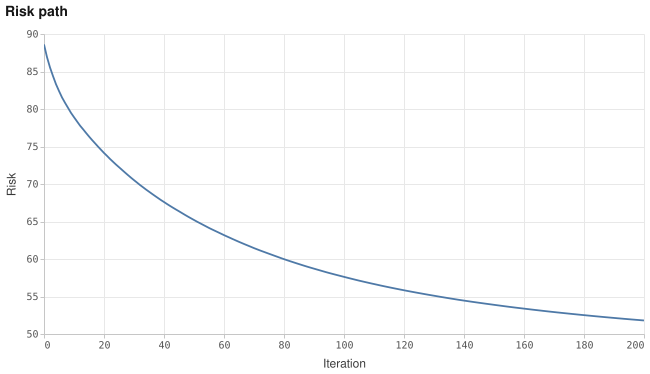

In [2]:
mb.plot.plot_risk(fit)

## Out-of-sample performance

Accuracy on data the model has not seen can be measured without knowing the
truth. The procedure below is repeated on fresh null data sets, each time
holding out a test set of the same size.


In [3]:
replicates = 40
rng = np.random.default_rng(7)
rows = []
for _ in range(replicates):
    x = rng.normal(size=(2 * n_obs, n_predictors))
    y = rng.normal(size=2 * n_obs)
    train = {f"x{j}": x[:n_obs, j] for j in range(n_predictors)}
    train["y"] = y[:n_obs]
    test = {f"x{j}": x[n_obs:, j] for j in range(n_predictors)}
    test["y"] = y[n_obs:]
# Fix the random draw so the resampling result is reproducible.
    model = mb.glmboost(f"y ~ {terms}", data=train, family=mb.Gaussian(),
                        control=mb.boost_control(200, 0.1))
    fitted = np.asarray(model.fitted_)
    predicted = np.asarray(model.predict(newdata=test))
    coefficients = {k: v for k, v in model.coef().items()
                    if k not in ("(Intercept)", "(offset)")}
    rows.append({
        "selected": len(coefficients),
        "r2_in": 1 - np.var(train["y"] - fitted) / np.var(train["y"]),
        "r2_out": 1 - np.var(test["y"] - predicted) / np.var(test["y"]),
        "largest_coef": max((abs(np.asarray(v)).max() for v in coefficients.values()),
                            default=0.0),
    })

summary = pl.DataFrame(rows)
print(f"across {replicates} null datasets:")
print(f"  terms selected        mean {summary['selected'].mean():5.1f} of {n_predictors}")
print(f"  in-sample R-squared   mean {summary['r2_in'].mean():+.3f}")
print(f"  out-of-sample         mean {summary['r2_out'].mean():+.3f}")
print(f"  largest coefficient   mean {summary['largest_coef'].mean():.3f}  (truth: 0)")


across 40 null datasets:
  terms selected        mean  23.8 of 40
  in-sample R-squared   mean +0.317
  out-of-sample         mean -0.214
  largest coefficient   mean 0.207  (truth: 0)


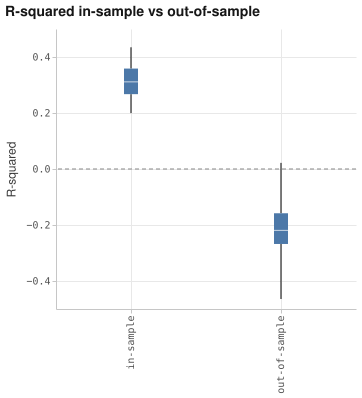

In [4]:
import altair as alt

r2_long = pl.concat([
    summary.select(pl.lit("in-sample").alias("setting"), pl.col("r2_in").alias("r2")),
    summary.select(pl.lit("out-of-sample").alias("setting"), pl.col("r2_out").alias("r2")),
])
zero_line = alt.Chart(pl.DataFrame({"r2": [0.0]})).mark_rule(
    color="#888888", strokeDash=[4, 3], strokeWidth=1
).encode(y="r2:Q")
boxplot = alt.Chart(r2_long).mark_boxplot(extent="min-max").encode(
    x=alt.X("setting:N", title=None),
    y=alt.Y("r2:Q", title="R-squared"),
)
alt.layer(boxplot, zero_line).properties(
    title="R-squared in-sample vs out-of-sample",
    width=300, height=280,
)

Across 40 null data sets the in-sample R-squared averages +0.317 and the
out-of-sample R-squared averages −0.214. A negative out-of-sample R-squared
means the model predicts worse than the response mean would.

The mechanism is selection. A coefficient of 0.2 obtained by keeping the
largest of 40 noise variables estimates the maximum of 40 noise coefficients,
not the effect of that predictor. The expected maximum of 40 draws is positive
even when every underlying effect is zero. A confidence interval computed after
selection does not correct for this, because it conditions on the same data
that performed the selection.


## Extension: stability selection

Stability selection controls an error rate that does not depend on the terms
having been chosen first. It refits the model on many subsamples, records how
often each term is selected, and takes a bound on the expected number of false
positives — the per-family error rate, or PFER — as an input. The cutoff on
selection frequency follows from that bound.


In [5]:
rng = np.random.default_rng(7)
plain, stable = [], []
for _ in range(20):
    data = null_dataset(rng)
    model = mb.glmboost(f"y ~ {terms}", data=data, family=mb.Gaussian(),
                        control=mb.boost_control(200, 0.1))
    plain.append(len([k for k in model.coef()
                      if k not in ("(Intercept)", "(offset)")]))
    stable.append(len(mb.stabsel(model, q=5, PFER=1.0, B=25).selected))

print(f"on {len(plain)} null datasets:")
print(f"  plain fit            selected {np.mean(plain):5.1f} terms on average")
print(f"  stability selection  selected {np.mean(stable):5.2f} terms on average")
print(f"  runs where stability selection returned nothing: "
      f"{sum(1 for s in stable if s == 0)}/{len(stable)}")

on 20 null datasets:
  plain fit            selected  23.4 terms on average
  stability selection  selected  0.50 terms on average
  runs where stability selection returned nothing: 12/20


Across 20 null data sets the plain fit selected 23.4 terms on average and
stability selection selected 0.5, returning nothing in 12 of the 20 runs.

Stability selection is conservative and costs `B` refits, and it will miss weak
effects that are genuine. Under the stability-selection assumptions, the PFER bound limits the expected
number of false positives to about one.


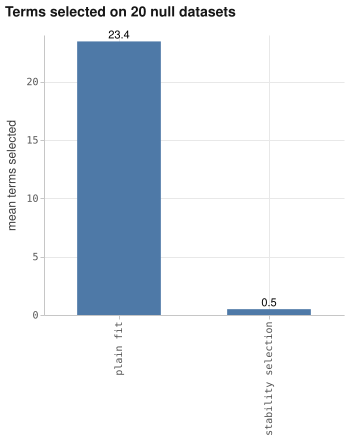

In [6]:
import altair as alt

counts = pl.DataFrame({
    "procedure": ["plain fit", "stability selection"],
    "terms": [float(np.mean(plain)), float(np.mean(stable))],
})
bars = alt.Chart(counts).mark_bar(color="#4e79a7").encode(
    x=alt.X("procedure:N", title=None),
    y=alt.Y("terms:Q", title="mean terms selected"),
)
labels = alt.Chart(counts).mark_text(dy=-6, fontSize=11).encode(
    x=alt.X("procedure:N", title=None),
    y=alt.Y("terms:Q"),
    text=alt.Text("terms:Q", format=".1f"),
)
alt.layer(bars, labels).properties(
    title="Terms selected on 20 null datasets",
    width=300, height=280,
)

The fit from the first section is one of the runs in which a single noise
variable crossed the cutoff. Its selection frequencies show one variable above
the cutoff and the other 39 below it.


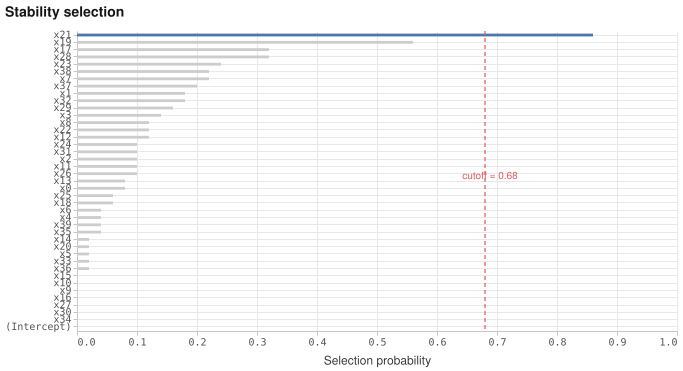

In [7]:
stabsel_result = mb.stabsel(fit, q=5, PFER=1.0, B=25)
mb.plot.plot_stabsel(stabsel_result)

## Extension: conformal prediction

Split conformal produces intervals with valid marginal coverage when rows are
exchangeable (see [](../methodology/conformal.ipynb)) and the specification is chosen without using calibration
responses. It does not require the model family or noise distribution to be
correct. It calibrates the width on
held-out residuals, so a model that has selected noise produces wide intervals
rather than narrow ones.


In [8]:
rng = np.random.default_rng(11)
data = null_dataset(rng, rows=400)
model = mb.glmboost(f"y ~ {terms}", data=data, family=mb.Gaussian(),
                    control=mb.boost_control(200, 0.1))
interval = mb.conformal_interval(model, level=0.9, seed=1)
observed = np.asarray(data["y"])
print(f"conformal 90% interval: coverage "
      f"{interval.empirical_coverage(observed) * 100:.1f}%, "
      f"mean width {float(np.mean(interval.width)):.2f}")
print(f"response sd {observed.std(ddof=1):.2f} — the interval is about as wide "
      f"as knowing nothing, which is the honest answer here")

conformal 90% interval: coverage 92.2%, mean width 3.54
response sd 1.01 — the interval is about as wide as knowing nothing, which is the honest answer here


The 90% interval covers 92.2% of held-out observations with a mean width of
3.54, against a response standard deviation of 1.01. An interval computed
without any model would span about ±1.65 standard deviations, a width near 3.3.
The calibrated interval is close to that, which reflects how little information
the model carries: calibration residuals remain large because the fitted predictors carry little
information about a new response.


## Conclusions

Selecting a term using the same data that estimate its coefficient can bias
the reported magnitude upward. On data where every true coefficient is zero, the procedure
reported 24 of them, the largest at +0.237, with an in-sample R-squared of
+0.317 against −0.214 out of sample.

With real signal, a selected coefficient combines the underlying association
with selection bias. An interval that treats the selected specification as fixed
can consequently miss its stated coverage.

Stability selection and split conformal address different uncertainty under
their stated assumptions. Stability selection returned nothing
in 12 of 20 null runs and averaged 0.5 selected terms against the plain fit's
23.4. The conformal interval covered 92.2% against a nominal 90%.

Selection is part of the estimator, so an evaluation has to include it — and
that holds for any procedure that chooses its terms from the data it then
reports, boosting or otherwise. Four designs allow for it, and they differ in
what they give up:

| design | what it gives up | what it supports |
|---|---|---|
| Pre-specify the model | flexibility | ordinary inference |
| Split the sample | power, by half the data | inference on the estimation half |
| Stability selection with a PFER | power | a stated error rate through selection |
| Conformal intervals | claims about coefficients | calibrated prediction |

A diagnostic that does not require knowing the truth is to run the whole
pipeline on a response with the signal removed, either permuted or replaced
with noise. The output is what the pipeline produces on its own, measured on
the same scale as the reported finding.
